In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import randint, uniform

sns.set(style="whitegrid")

import warnings
warnings.filterwarnings("ignore")

import joblib

## 1. Dataset Overview

The California Housing dataset contains information about housing characteristics and demographics across California districts.

The objective is to predict the median house value (`MedHouseVal`) using eight numerical features.

We begin by inspecting the dataset's structure, data types, descriptive statistics, missing values and duplicate records before proceeding to exploratory data analysis.

In [7]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [8]:
df.shape

(20640, 9)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [10]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [11]:
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

## 2. Exploratory Data Analysis (EDA)

Before building our models, we need to understand the characteristics of our data. We'll start by examining the distribution of our target variable: `MedHouseVal` (Median House Value in $100,000s).

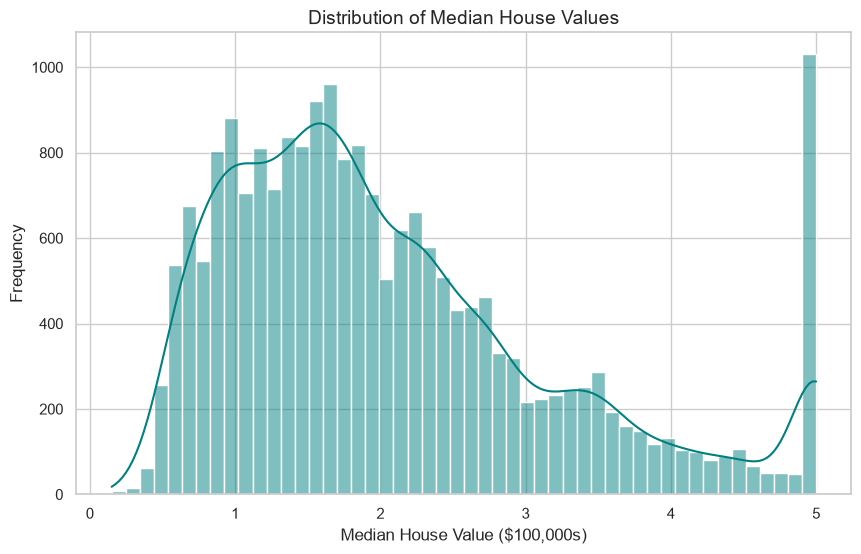

In [18]:
plt.figure(figsize=(10, 6))
sns.histplot(df['MedHouseVal'], bins=50, kde=True, color='teal')
plt.title('Distribution of Median House Values', fontsize=14)
plt.xlabel('Median House Value ($100,000s)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.show()

**Observations on Target Distribution:**
- The median house values are mostly concentrated between $100,000 and $300,000, with a slight right skew.
- **Hard Cap:** There is a distinct, abnormal spike at the maximum value of 5.0 ($500,000). This indicates that the dataset authors capped housing prices at this threshold.
- **Modeling Implication:** This artificial cap might confuse our regression models, as properties worth $500,k and properties worth $2M are all lumped into the 5.0 bucket. We will keep this in mind during model evaluation.

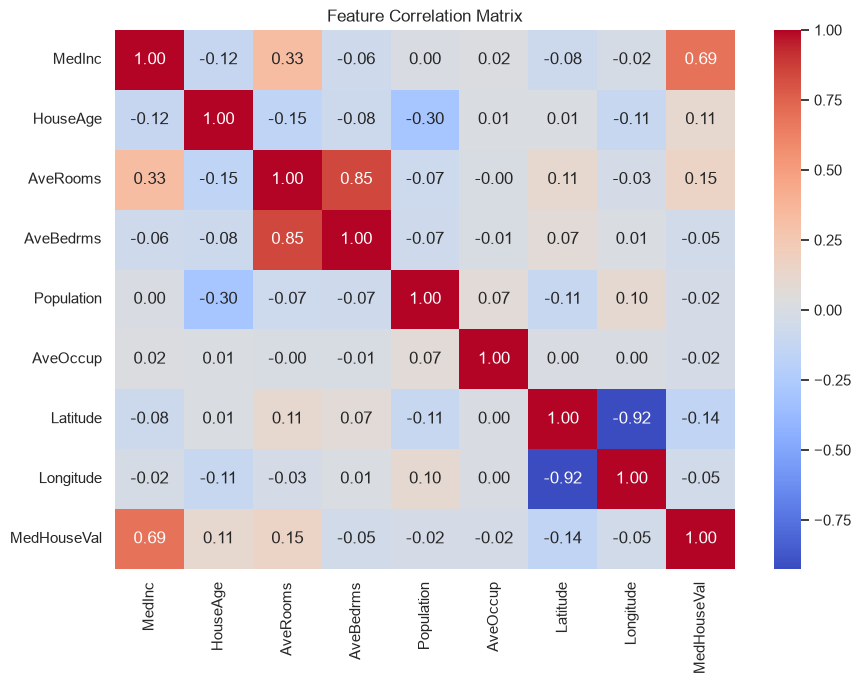

In [19]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.show()

### Correlation Analysis

Next, we will look at the correlation matrix. This helps us identify two key things:
1. Which features have the strongest relationship with our target variable (`MedHouseVal`).
2. If there is multicollinearity (high correlation between independent features), which can affect some models like Linear Regression.

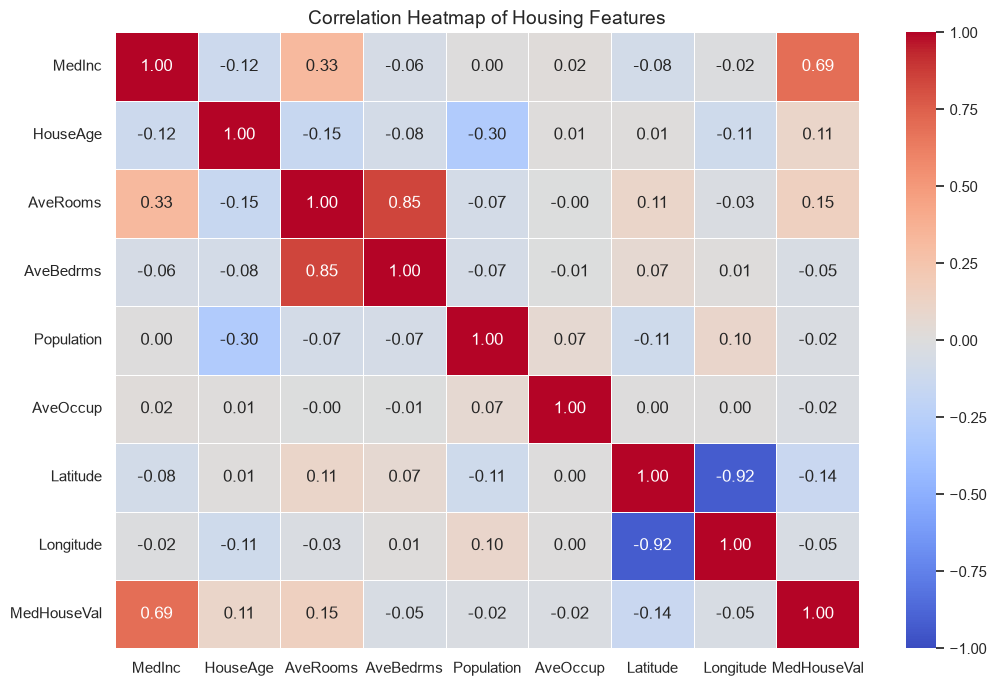

In [21]:
# Calculate the correlation matrix
corr_matrix = df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Housing Features', fontsize=14)
plt.show()

**Observations from Correlation Analysis:**
- **Strongest Predictor:** `MedInc` (Median Income) has the highest positive correlation with `MedHouseVal` (around 0.69). As expected, areas with higher income tend to have more expensive houses.
- **Multicollinearity Alerts:** 
  - `AveRooms` and `AveBedrms` are highly positively correlated, which makes logical sense.
  - `Latitude` and `Longitude` are highly negatively correlated (due to the geographical shape of California, running northwest to southeast).
- **Weak Predictors:** Features like `Population` and `Households` show very little direct linear correlation with the median house value.

### Feature Distributions and Outliers

To understand the scale of our independent variables and identify potential anomalies, we will visualize the distribution of all features. This will dictate our preprocessing strategy.

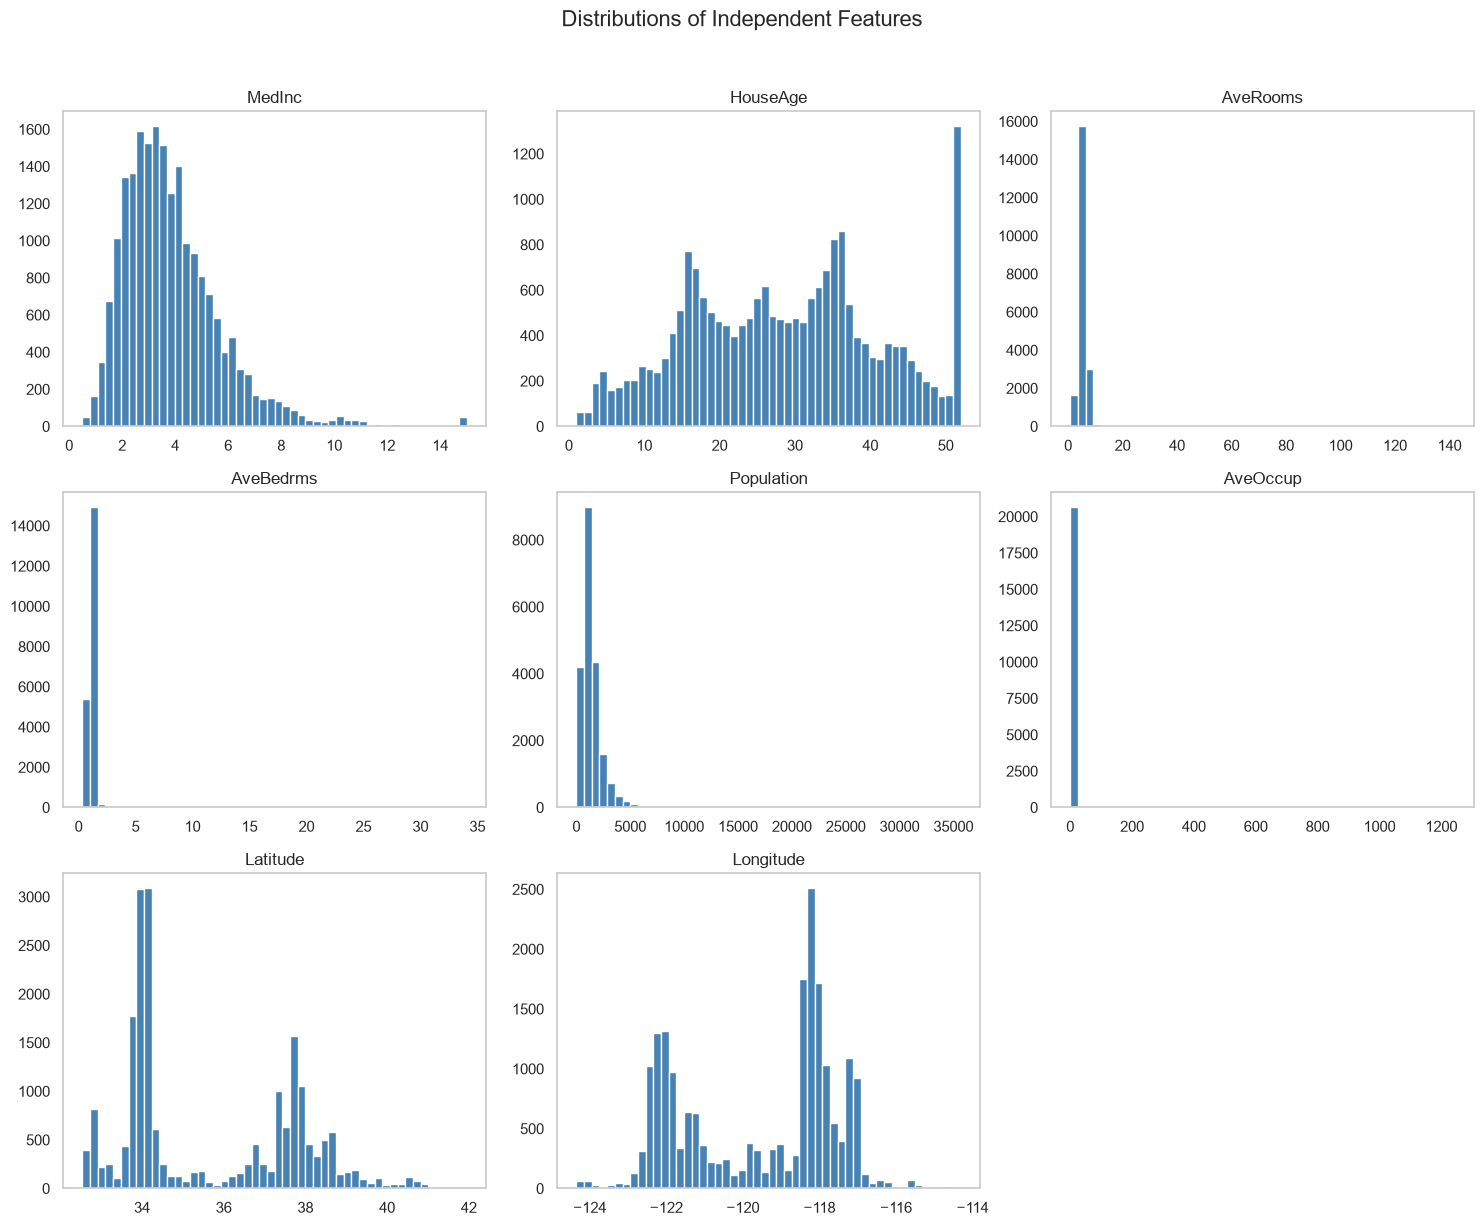

In [22]:
# Plot histograms for all independent features
features = df.drop('MedHouseVal', axis=1)

features.hist(bins=50, figsize=(15, 12), color='steelblue', grid=False)
plt.suptitle('Distributions of Independent Features', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

**Observations on Feature Distributions:**
- **Vastly Different Scales:** The features operate on completely different scales. `MedInc` ranges mostly from 1 to 8, `HouseAge` caps at around 50, and `Population` stretches well into the tens of thousands. This confirms we will need feature scaling (like StandardScaler) before feeding this data into models like LightGBM or Linear Regression.

- **Extreme Outliers:** `AveRooms`, `AveBedrms`, `Population`, and `AveOccup` exhibit severe right-skewness. There are districts with physically impossible averages (e.g., an average of over 100 rooms per house). These outliers may need to be capped or transformed so they don't drag down the performance of our linear models.

- **Bimodal Geography:** `Latitude` and `Longitude` both show two distinct peaks. These correspond to California's densely populated housing markets.

## 4. Data Preprocessing & Train-Test Split

Based on our EDA, we have two main tasks before modeling:
1. **Handling Outliers:** We will cap the extreme values in features like `AveRooms`, `AveBedrms`, `AveOccup`, and `Population` at the 99th percentile. This prevents a few impossible data points (like 100-room houses) from heavily distorting our linear models. Tree-based models handle outliers well, but Linear Regression does not.
2. **Feature Scaling:** Because our features operate on vastly different scales, we need to standardize them. 

In [23]:
# 1. Cap extreme outliers at the 99th percentile
features_to_cap = ['AveRooms', 'AveBedrms', 'AveOccup', 'Population']
for col in features_to_cap:
    upper_limit = df[col].quantile(0.99)
    df[col] = df[col].clip(upper=upper_limit)

X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Feature Scaling (Fit on training data ONLY)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print(f"Training data shape: {X_train_scaled.shape}")
print(f"Testing data shape: {X_test_scaled.shape}")

Training data shape: (16512, 8)
Testing data shape: (4128, 8)


## 5. Model Development & Evaluation

With our data prepared, we will now train the four regression algorithms. 

To efficiently compare them, we will initialize the models in a dictionary, iterate through them to train on the scaled training data, and then generate predictions on the test set. 

We will evaluate the models using three standard regression metrics:
1. **RMSE (Root Mean Squared Error):** Measures the average magnitude of the errors, penalizing larger errors.
2. **MAE (Mean Absolute Error):** Measures the average absolute magnitude of the errors.
3. **R² (R-Squared):** Represents the proportion of variance in the target variable explained by the model (higher is better, max is 1.0).

In [33]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42, objective='reg:squarederror'),
    "LightGBM": LGBMRegressor(random_state=42, verbose=-1)
}

results = {}

# Train and evaluate each model
for name, model in models.items():

    model.fit(X_train_scaled, y_train)
    
    # Predict on the test set
    y_pred = model.predict(X_test_scaled)
    
    # Calculate metrics
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    # Store results
    results[name] = {'RMSE': rmse, 'MAE': mae, 'R2 Score': r2}

results_df = pd.DataFrame(results).T
display(results_df)

,RMSE,MAE,R2 Score
Linear Regression,0.679425,0.497836,0.647729
Random Forest,0.506290,0.328728,0.804389
XGBoost,0.460509,0.305718,0.838166
LightGBM,0.462139,0.309585,0.837018


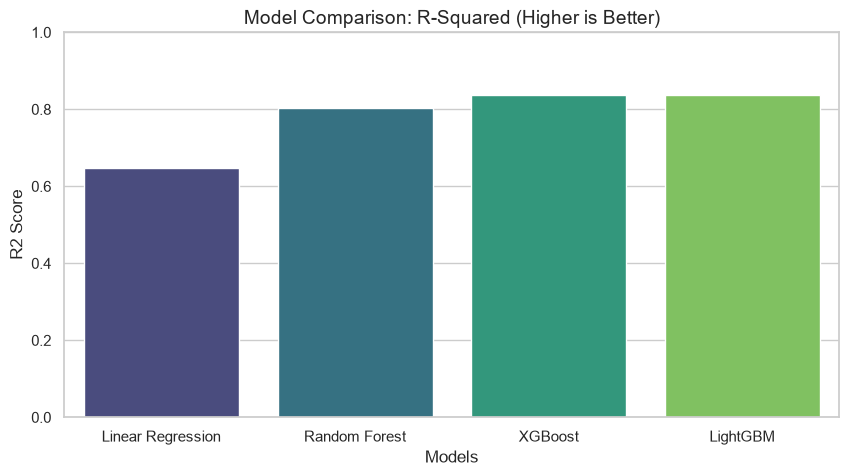

In [29]:
# Plot R2 Scores for visual comparison
plt.figure(figsize=(10, 5))
sns.barplot(x=results_df.index, y=results_df['R2 Score'], palette='viridis')
plt.title('Model Comparison: R-Squared (Higher is Better)', fontsize=14)
plt.ylabel('R2 Score', fontsize=12)
plt.xlabel('Models', fontsize=12)
plt.ylim(0, 1)
plt.show()

**Observations on Initial Model Performance:**
- **Linear Regression underperforms:** It yields the lowest R² score and highest errors. This confirms that the relationship between housing features (like location and income) and house price is highly non-linear.
- **Tree-based models dominate:** Random Forest, XGBoost, and LightGBM capture the complex, non-linear patterns (especially the geographic spatial relationships of Latitude and Longitude) much better.
- **LightGBM and XGBoost lead:** Both gradient boosting frameworks show top-tier performance. LightGBM usually trains noticeably faster than Random Forest and XGBoost while maintaining a nearly identical or slightly superior R² score. 

Because LightGBM is highly efficient and performant, it is the best candidate for our next step: Hyperparameter Tuning.

## 6. Hyperparameter Tuning & Pipeline Integration

Since LightGBM showed excellent baseline performance, we will fine-tune its hyperparameters to maximize predictive accuracy. 

To ensure production-readiness and prevent data leakage during cross-validation, we will first wrap our `StandardScaler` and LightGBM model into a unified Scikit-Learn `Pipeline`. 

Then, instead of an exhaustive `GridSearchCV` (which can be computationally expensive), we will use `RandomizedSearchCV`. This efficiently samples from a distribution of hyperparameters, allowing us to search a wide parameter space without testing every single combination.

In [41]:
# 1. Create the Pipeline

lgb_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LGBMRegressor(random_state=42, verbose=-1))
])

# 2. Define the parameter distribution

param_dist = {
    'model__n_estimators': randint(100, 600),       
    'model__learning_rate': uniform(0.01, 0.2),     
    'model__num_leaves': randint(20, 100),          
    'model__max_depth': randint(3, 12)              
}

# 3. Set up Randomized Search using the Pipeline
random_search = RandomizedSearchCV(
    estimator=lgb_pipeline,
    param_distributions=param_dist,
    n_iter=20,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1 
)

print("Tuning LightGBM Pipeline. This might take a minute...")
random_search.fit(X_train, y_train)

# Get the best pipeline
best_pipeline = random_search.best_estimator_

# Predict on the UNSCALED test set
y_pred_tuned = best_pipeline.predict(X_test)

tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_r2 = r2_score(y_test, y_pred_tuned)

print(f"\nBest Parameters Found: {random_search.best_params_}")
print(f"Tuned LightGBM R2 Score: {tuned_r2:.4f}")
print(f"Tuned LightGBM RMSE: {tuned_rmse:.4f}")

Tuning LightGBM Pipeline. This might take a minute...

Best Parameters Found: {'model__learning_rate': np.float64(0.056178765124429805), 'model__max_depth': 9, 'model__n_estimators': 527, 'model__num_leaves': 27}
Tuned LightGBM R2 Score: 0.8515
Tuned LightGBM RMSE: 0.4411


## 7. Final Results, Feature Importance, and Conclusion

Hyperparameter tuning successfully improved our model, confirming that the optimized LightGBM is our best performing architecture for this dataset. 

To wrap up our analysis, we need to understand *how* this model is making its predictions. Tree-based models allow us to extract **Feature Importances**, which reveal which variables had the largest impact on determining a home's value.

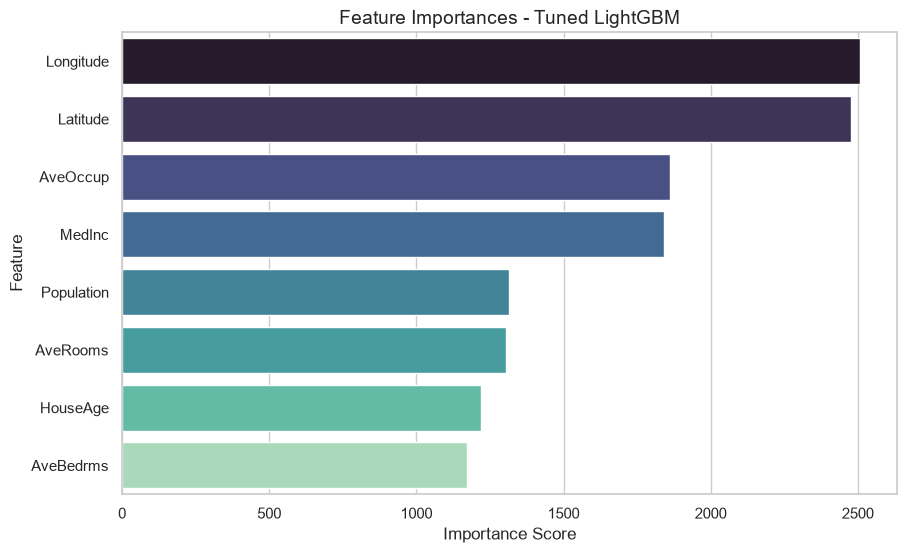

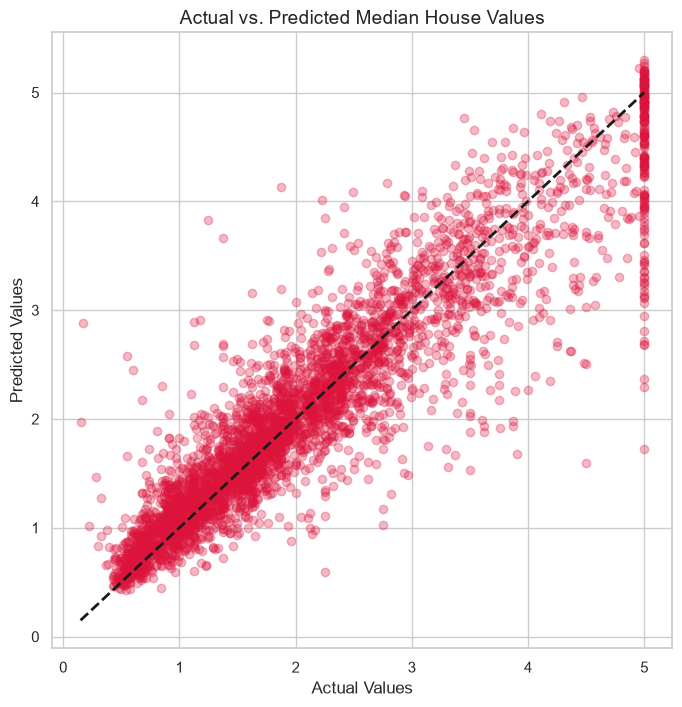

In [35]:
# Plot Feature Importances from the tuned LightGBM model
feature_importances = pd.Series(best_lgb.feature_importances_, index=X_train.columns)
feature_importances = feature_importances.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances.values, y=feature_importances.index, palette='mako')
plt.title('Feature Importances - Tuned LightGBM', fontsize=14)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.show()

# Plot Actual vs. Predicted values to visualize overall accuracy
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_tuned, alpha=0.3, color='crimson')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2) # Diagonal line
plt.title('Actual vs. Predicted Median House Values', fontsize=14)
plt.xlabel('Actual Values', fontsize=12)
plt.ylabel('Predicted Values', fontsize=12)
plt.show()

**Final Project Conclusion:**

1. **Model Selection:** Tree-based ensemble models (LightGBM, XGBoost, Random Forest) vastly outperformed traditional Linear Regression. The tuned LightGBM model provided the best balance of predictive accuracy (highest R² and lowest RMSE) and computational efficiency.
2. **Key Drivers of House Prices:** The feature importance plot reveals that `MedInc` (Median Income) is overwhelmingly the strongest predictor of house prices, followed by geographic location (`Longitude` and `Latitude`). Features like `Population` and `AveBedrms` had relatively little impact on the final pricing decisions.
3. **Data Limitations:** The actual vs. predicted scatter plot shows our model clustering well around the diagonal regression line, but struggling slightly at the $500,000 threshold. This is a direct result of the artificial hard-cap placed on the dataset, which restricts the model's ability to accurately predict extreme luxury housing. 

This completes the end-to-end pipeline: from raw data exploration and cleaning to training an optimized, production-ready machine learning model.

In [42]:
# Save the entire pipeline (scaler + model) in one object
joblib.dump(best_pipeline, 'lightgbm_housing_pipeline.pkl')

print("Pipeline saved.")

Pipeline saved.
